<div style="background:#0B2545;color:white;padding:18px 22px;border-radius:8px">
<div style="font-size:12px;letter-spacing:2px;opacity:.8">DATABANK ACADEMY · PROGRAMA EJECUTIVO EN GESTIÓN INTEGRAL DEL RIESGO DE CRÉDITO MINORISTA</div>
<div style="font-size:24px;font-weight:700;margin-top:6px">Módulo 3 · Sesión 4: Construcción del scorecard, discriminación, calibración y decisiones</div>
<div style="font-size:14px;margin-top:4px;opacity:.9">Laboratorio: escalamiento por PDO a mano y con optbinning, AUC/KS/CAP, recalibración, cortes por utilidad, bandas, razones y monitoreo</div>
</div>

## Objetivos de la sesión (2 horas)

1. Construir un **scorecard** a partir de una logística sobre WoE: escalamiento por **PDO** (puntos para duplicar los odds), a mano y con `optbinning.Scorecard`.
2. Evaluar la **discriminación** (AUC, Gini, KS, curva CAP) en desarrollo y fuera de tiempo.
3. Evaluar y corregir la **calibración**: calibración global, por bandas, recalibración del intercepto, Platt e isotónica.
4. Elegir **puntos de corte** con matrices de confusión y criterio de rentabilidad.
5. Traducir coeficientes y probabilidades en **decisiones de riesgo**: tabla de odds, bandas de riesgo, razones de rechazo y monitoreo (PSI).

| Bloque | Tiempo | Contenido |
|---|---|---|
| 1 | 30 min | Del modelo al scorecard: escalamiento por PDO |
| 2 | 20 min | Discriminación: AUC, Gini, KS, CAP |
| 3 | 25 min | Calibración y recalibración |
| 4 | 20 min | Matrices de confusión y puntos de corte |
| 5 | 15 min | Decisiones: bandas, razones de rechazo, monitoreo |
| 6 | 10 min | Ejercicios |

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .3, "font.size": 11})
AZUL, ROJO, VERDE, GRIS, ORO = "#0B2545", "#C8102E", "#2E8B57", "#8D99AE", "#E0A100"
DATA = Path("../datos")

import warnings; warnings.filterwarnings("ignore")
from optbinning import BinningProcess, Scorecard
from optbinning.scorecard import ScorecardMonitoring
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss, log_loss, confusion_matrix
from scipy import stats
app = pd.read_csv(DATA / "hc_application_sintetico.csv").drop_duplicates()
app["EDAD"] = -app.DAYS_BIRTH / 365.25
app["RCI"] = app.AMT_ANNUITY / (app.AMT_INCOME_TOTAL / 12)
app["OCCUPATION_TYPE"] = app.OCCUPATION_TYPE.fillna("Sin dato")
dev = app[app.FECHA_SOLICITUD < "2025-01"].copy(); oot = app[app.FECHA_SOLICITUD >= "2025-01"].copy()
VARS = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "EDAD", "RCI", "DAYS_EMPLOYED", "NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE",
        "OCCUPATION_TYPE", "CODE_GENDER", "REGION_RATING_CLIENT", "AGENCIA_ID"]
CATS = [v for v in VARS if app[v].dtype == object]
params = {"EXT_SOURCE_1": {"monotonic_trend": "descending"}, "EXT_SOURCE_2": {"monotonic_trend": "descending"}, "EXT_SOURCE_3": {"monotonic_trend": "descending"},
          "EDAD": {"monotonic_trend": "descending"}, "RCI": {"monotonic_trend": "ascending"},
          "DAYS_EMPLOYED": {"special_codes": [365243], "monotonic_trend": "auto_asc_desc"}, "AGENCIA_ID": {"cat_cutoff": 0.003, "max_n_bins": 6}}
bp = BinningProcess(VARS, categorical_variables=CATS, binning_fit_params=params, min_bin_size=0.04, max_n_bins=8)
bp.fit(dev[VARS], dev.TARGET)
W_dev, W_oot = bp.transform(dev[VARS], metric="woe"), bp.transform(oot[VARS], metric="woe")
print("Variables:", VARS)

Variables: ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'EDAD', 'RCI', 'DAYS_EMPLOYED', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'OCCUPATION_TYPE', 'CODE_GENDER', 'REGION_RATING_CLIENT', 'AGENCIA_ID']


## 1. Del modelo al scorecard: escalamiento por PDO
Con WoE $= \ln(\%buenos/\%malos)$ y la logística $\ln\frac{p}{1-p} = \alpha + \sum_j \beta_j\, WoE_j$ (donde $p$ = probabilidad de **malo**), los odds **buenos:malos** son $\ln(\text{odds}) = -(\alpha + \sum_j \beta_j WoE_j)$.

El score es una transformación lineal de esos log-odds:
$$\text{Score} = \text{Offset} + \text{Factor}\cdot\ln(\text{odds}) \qquad \text{Factor} = \frac{PDO}{\ln 2} \qquad \text{Offset} = S_0 - \text{Factor}\cdot\ln(\text{odds}_0)$$

**Convención del caso:** 600 puntos ↔ odds 50:1 y **PDO = 20** (cada 20 puntos se duplican los odds). Los puntos de cada atributo $i$ de la variable $j$ (con $k$ variables):
$$\text{Puntos}_{ij} = -\left(\beta_j\, WoE_{ij} + \frac{\alpha}{k}\right)\text{Factor} + \frac{\text{Offset}}{k}$$

In [2]:
lr = LogisticRegression(C=1e6, max_iter=5000).fit(W_dev, dev.TARGET)
alpha, beta = lr.intercept_[0], pd.Series(lr.coef_[0], index=VARS)
print("Coeficientes sobre WoE: −1 si cada variable estuviera sola; menores en valor absoluto por la correlación entre variables"); print(beta.round(3).to_string())
PDO, S0, ODDS0 = 20, 600, 50
factor = PDO / np.log(2); offset = S0 - factor * np.log(ODDS0); k = len(VARS)
filas = []
for v in VARS:
    bt = bp.get_binned_variable(v).binning_table.build().drop(index="Totals")
    for _, r in bt.iterrows():
        if r["Count"] == 0: continue
        filas.append({"Variable": v, "Tramo": str(r["Bin"]), "WoE": r["WoE"], "Puntos": -(beta[v] * r["WoE"] + alpha / k) * factor + offset / k})
tabla = pd.DataFrame(filas)
print(f"\nFactor = {factor:.3f} | Offset = {offset:.2f}")
tabla[tabla.Variable.isin(["EXT_SOURCE_2", "DAYS_EMPLOYED", "NAME_INCOME_TYPE"])].style.format({"WoE": "{:+.3f}", "Puntos": "{:.1f}"}).hide(axis="index")

Coeficientes sobre WoE: −1 si cada variable estuviera sola; menores en valor absoluto por la correlación entre variables
EXT_SOURCE_1           -0.3540
EXT_SOURCE_2           -0.6290
EXT_SOURCE_3           -0.4670
EDAD                   -0.4990
RCI                    -0.8690
DAYS_EMPLOYED          -0.7710
NAME_INCOME_TYPE       -0.2990
NAME_EDUCATION_TYPE    -0.8700
OCCUPATION_TYPE        -0.5060
CODE_GENDER            -0.8380
REGION_RATING_CLIENT   -0.8790
AGENCIA_ID             -1.0720

Factor = 28.854 | Offset = 487.12


Variable,Tramo,WoE,Puntos
EXT_SOURCE_2,"(-inf, 0.27)",-1.559,18.2
EXT_SOURCE_2,"[0.27, 0.37)",-0.842,31.2
EXT_SOURCE_2,"[0.37, 0.49)",-0.376,39.7
EXT_SOURCE_2,"[0.49, 0.59)",-0.013,46.2
EXT_SOURCE_2,"[0.59, 0.64)",+0.273,51.4
EXT_SOURCE_2,"[0.64, 0.71)",+0.526,56.0
EXT_SOURCE_2,"[0.71, 0.82)",+0.909,63.0
EXT_SOURCE_2,"[0.82, inf)",+1.820,79.5
EXT_SOURCE_2,Missing,+0.804,61.1
DAYS_EMPLOYED,"(-inf, -4524.50)",+0.688,61.8


Diferencia máxima entre suma de puntos y fórmula: 2.27e-13


Correlación score manual vs. optbinning: 1.000000 | medias: 573.7 vs. 573.7


,Variable,Bin,Count,Event rate,WoE,Coefficient,Points
0,RCI,"(-inf, 0.08)",2511,0.0661,0.2955,-0.8690,53.8895
1,RCI,"[0.08, 0.13)",6001,0.0697,0.2395,-0.8690,52.4841
2,RCI,"[0.13, 0.25)",12692,0.0737,0.1792,-0.8690,50.9710
3,RCI,"[0.25, 0.49)",13582,0.0811,0.0745,-0.8690,48.3469
4,RCI,"[0.49, 0.60)",2906,0.0984,-0.1376,-0.8690,43.0296
5,RCI,"[0.60, 0.76)",2701,0.1055,-0.2151,-0.8690,41.0849
6,RCI,"[0.76, 1.01)",2262,0.1229,-0.3873,-0.8690,36.7689
7,RCI,"[1.01, inf)",2437,0.1834,-0.8592,-0.8690,24.9360
8,RCI,Special,0,0.0000,0.0000,-0.8690,46.4790
9,RCI,Missing,0,0.0000,0.0000,-0.8690,46.4790


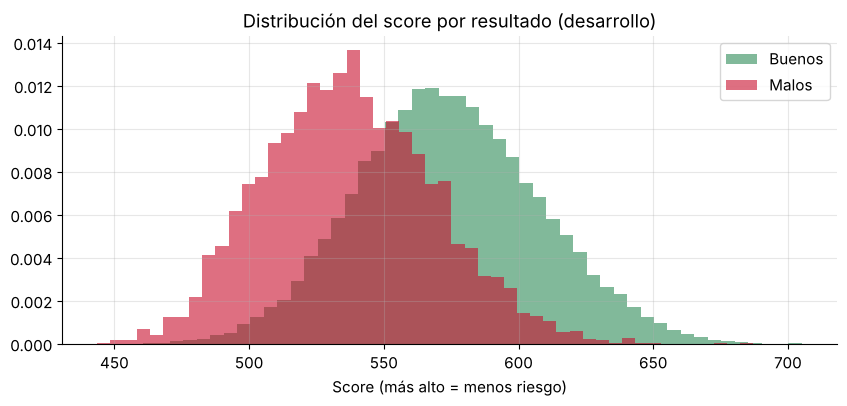

In [3]:
def score_manual(W):
    return offset + factor * (-(alpha + W.values @ beta.values))
s_dev, s_oot = score_manual(W_dev), score_manual(W_oot)
# Verificación: la suma de puntos por atributo reproduce el score
pts = np.zeros(len(oot))
bins_oot = bp.transform(oot[VARS], metric="woe")
for v in VARS:
    pts += -(beta[v] * bins_oot[v].values + alpha / k) * factor + offset / k
print(f"Diferencia máxima entre suma de puntos y fórmula: {np.abs(pts - s_oot).max():.2e}")
# El mismo scorecard con optbinning
sc = Scorecard(binning_process=bp, estimator=LogisticRegression(C=1e6, max_iter=5000), scaling_method="pdo_odds",
               scaling_method_params={"pdo": PDO, "odds": ODDS0, "scorecard_points": S0}, intercept_based=False, reverse_scorecard=False)
sc.fit(dev[VARS], dev.TARGET)
s_ob = sc.score(oot[VARS])
print(f"Correlación score manual vs. optbinning: {np.corrcoef(s_oot, s_ob)[0, 1]:.6f} | medias: {s_oot.mean():.1f} vs. {s_ob.mean():.1f}")
display(sc.table(style="detailed").query("Variable == 'RCI'")[["Variable", "Bin", "Count", "Event rate", "WoE", "Coefficient", "Points"]])
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(s_dev[dev.TARGET == 0], bins=50, alpha=.6, color=VERDE, density=True, label="Buenos"); ax.hist(s_dev[dev.TARGET == 1], bins=50, alpha=.6, color=ROJO, density=True, label="Malos")
ax.set_xlabel("Score (más alto = menos riesgo)"); ax.legend(); ax.set_title("Distribución del score por resultado (desarrollo)"); plt.show()

**¿Por qué los coeficientes no son −1?** Una logística con una sola variable WoE tiene coeficiente −1 (el WoE ya es el log-odds relativo). Con varias variables correlacionadas, la regresión **reduce** el peso de cada una para no contar dos veces la misma evidencia: la misma idea del WoE condicional de la sesión 3. Un coeficiente con signo positivo (≥ 0) sería una alerta de multicolinealidad o de tramos inestables.

**Detalles de la API de optbinning:** `reverse_scorecard=False` produce la convención usual (**más puntos = menos riesgo**); con `True` el score crece con el riesgo. `intercept_based=True` reparte el intercepto como una constante separada en lugar de distribuirlo entre variables. `scaling_method="min_max"` es la alternativa cuando se quiere un rango fijo (p. ej., 0-1000).

## 2. Discriminación: AUC, Gini, KS y curva CAP

,AUC,Gini,KS
Desarrollo (2022-2024),0.7857,0.5714,0.4236
Fuera de tiempo (2025),0.7716,0.5433,0.4118


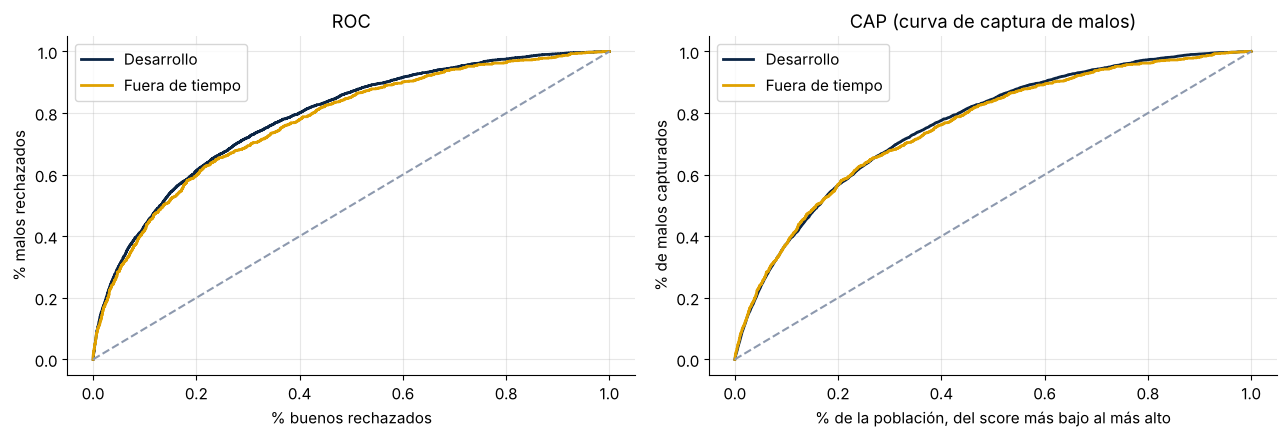

In [4]:
def metricas(y, s):
    auc = roc_auc_score(y, -s)                       # score alto = bueno, por eso el signo
    ks = stats.ks_2samp(s[y == 0], s[y == 1]).statistic
    return {"AUC": auc, "Gini": 2 * auc - 1, "KS": ks}
disc = pd.DataFrame({"Desarrollo (2022-2024)": metricas(dev.TARGET.values, s_dev), "Fuera de tiempo (2025)": metricas(oot.TARGET.values, s_oot)}).T
display(disc.style.format("{:.4f}"))
def cap(y, s):
    o = np.argsort(s); yy = y[o]                     # del más riesgoso (score bajo) al menos riesgoso
    return np.r_[0, np.arange(1, len(y) + 1) / len(y)], np.r_[0, np.cumsum(yy) / yy.sum()]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for nombre, y_, s_, c in [("Desarrollo", dev.TARGET.values, s_dev, AZUL), ("Fuera de tiempo", oot.TARGET.values, s_oot, ORO)]:
    fpr, tpr, _ = roc_curve(y_, -s_); ax[0].plot(fpr, tpr, color=c, lw=2, label=nombre)
    x_, y_c = cap(y_, s_); ax[1].plot(x_, y_c, color=c, lw=2, label=nombre)
ax[0].plot([0, 1], [0, 1], "--", color=GRIS); ax[0].set_title("ROC"); ax[0].legend(); ax[0].set_xlabel("% buenos rechazados"); ax[0].set_ylabel("% malos rechazados")
ax[1].plot([0, 1], [0, 1], "--", color=GRIS); ax[1].set_title("CAP (curva de captura de malos)"); ax[1].set_xlabel("% de la población, del score más bajo al más alto"); ax[1].set_ylabel("% de malos capturados"); ax[1].legend()
plt.tight_layout(); plt.show()

## 3. Calibración y recalibración
Un scorecard puede **ordenar bien y estar mal calibrado**. Para provisiones, precio y capital, la PD debe coincidir con la tasa observada.

- **Calibración global (calibration-in-the-large):** PD media predicha vs. tasa observada.
- **Por bandas:** PD predicha vs. observada por decil o por banda de score.
- **Recalibración:** (a) ajustar solo el **intercepto** a la tendencia central objetivo; (b) **Platt**: logística sobre el score; (c) **isotónica**: función monótona no paramétrica.

Desarrollo: PD media 8.68% vs. observada 8.69%
2025:       PD media 7.97% vs. observada 5.86%   <- el entorno 2025 es más benigno


,PD media,tasa observada,Brier,log-loss,Hosmer-Lemeshow,AUC
método,,,,,,
Original (desarrollo),7.85%,5.91%,0.05142,0.19568,54.2,0.7824
Intercepto,5.61%,5.91%,0.05071,0.19263,18.7,0.7824
Platt,5.64%,5.91%,0.05081,0.19281,19.0,0.7824
Isotónica,5.60%,5.91%,0.05107,0.19437,15.8,0.7784


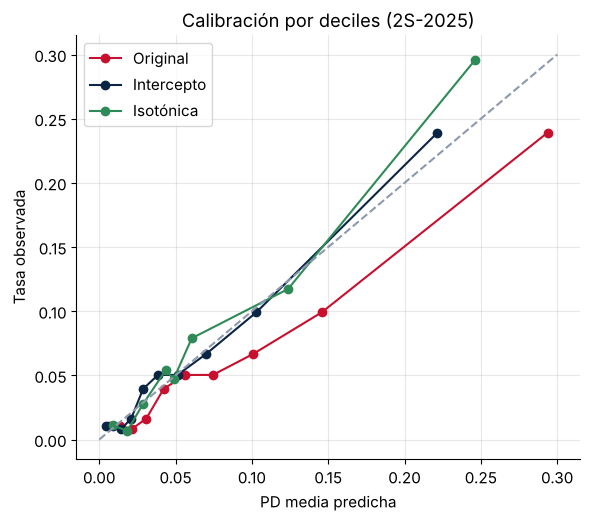

In [5]:
p_dev, p_oot = lr.predict_proba(W_dev)[:, 1], lr.predict_proba(W_oot)[:, 1]
print(f"Desarrollo: PD media {p_dev.mean():.2%} vs. observada {dev.TARGET.mean():.2%}")
print(f"2025:       PD media {p_oot.mean():.2%} vs. observada {oot.TARGET.mean():.2%}   <- el entorno 2025 es más benigno")
# Muestra de recalibración: primer semestre 2025; evaluación: segundo semestre 2025
cal = oot.FECHA_SOLICITUD < "2025-07"; ev = ~cal
y_cal, y_ev = oot.TARGET.values[cal], oot.TARGET.values[ev]
# (a) recalibración de intercepto: buscar delta tal que la PD media = tasa observada en la muestra de calibración
from scipy.optimize import brentq
logit_oot = np.log(p_oot / (1 - p_oot))
delta = brentq(lambda d: (1 / (1 + np.exp(-(logit_oot[cal] + d)))).mean() - y_cal.mean(), -3, 3)
p_int = 1 / (1 + np.exp(-(logit_oot + delta)))
# (b) Platt: logística de la variable objetivo sobre el logit original
platt = LogisticRegression(C=1e6).fit(logit_oot[cal].reshape(-1, 1), y_cal); p_platt = platt.predict_proba(logit_oot.reshape(-1, 1))[:, 1]
# (c) Isotónica
iso = IsotonicRegression(out_of_bounds="clip", y_min=1e-4, y_max=1 - 1e-4).fit(p_oot[cal], y_cal); p_iso = iso.predict(p_oot)
filas = []
for nombre, pp in [("Original (desarrollo)", p_oot), ("Intercepto", p_int), ("Platt", p_platt), ("Isotónica", p_iso)]:
    q = pp[ev]; g = pd.DataFrame({"p": q, "y": y_ev, "d": pd.qcut(q, 10, labels=False, duplicates="drop")}).groupby("d").agg(O=("y", "sum"), E=("p", "sum"), n=("y", "size"))
    hl = (((g.O - g.E) ** 2) / (g.E * (1 - g.E / g.n))).sum()
    filas.append({"método": nombre, "PD media": q.mean(), "tasa observada": y_ev.mean(), "Brier": brier_score_loss(y_ev, q), "log-loss": log_loss(y_ev, q),
                  "Hosmer-Lemeshow": hl, "AUC": roc_auc_score(y_ev, q)})
display(pd.DataFrame(filas).set_index("método").style.format({"PD media": "{:.2%}", "tasa observada": "{:.2%}", "Brier": "{:.5f}", "log-loss": "{:.5f}", "Hosmer-Lemeshow": "{:.1f}", "AUC": "{:.4f}"}))
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for nombre, pp, c in [("Original", p_oot, ROJO), ("Intercepto", p_int, AZUL), ("Isotónica", p_iso, VERDE)]:
    g = pd.DataFrame({"p": pp[ev], "y": y_ev}).assign(d=lambda t: pd.qcut(t.p, 10, labels=False, duplicates="drop")).groupby("d").mean()
    ax.plot(g.p, g.y, "o-", color=c, label=nombre)
ax.plot([0, .3], [0, .3], "--", color=GRIS); ax.set_xlabel("PD media predicha"); ax.set_ylabel("Tasa observada"); ax.legend(); ax.set_title("Calibración por deciles (2S-2025)"); plt.show()

**Lectura:** la recalibración **no cambia el ordenamiento** (el AUC del intercepto y de Platt es idéntico al original) pero corrige el nivel. En la práctica la recalibración de intercepto hacia una **tendencia central** (de largo plazo o del período, según el uso: provisiones point-in-time o capital through-the-cycle) es la más común, porque preserva la estructura del scorecard aprobado. La isotónica es flexible pero puede sobreajustar con pocos datos.

## 4. Matrices de confusión y puntos de corte
Cada punto de corte define una matriz de confusión. El corte se elige por **economía**, no por exactitud: ganancia de los buenos aprobados menos pérdida de los malos aprobados (supuestos del Módulo 1: margen sobre saldo promedio y pérdida por incumplimiento).

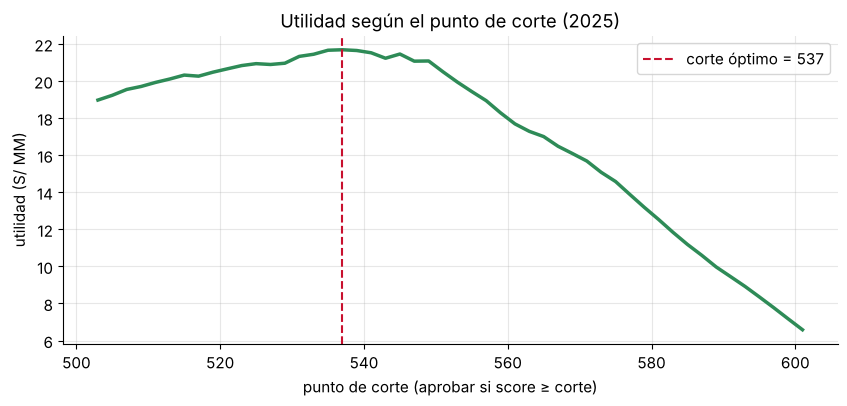

Corte 517: aprobación 94.9% | tasa de malos de aprobados 4.66% | malos rechazados (recall) 24.4% | buenos rechazados 3.9%
Corte 537: aprobación 85.7% | tasa de malos de aprobados 3.58% | malos rechazados (recall) 47.7% | buenos rechazados 12.2%
Corte 557: aprobación 67.9% | tasa de malos de aprobados 2.67% | malos rechazados (recall) 69.1% | buenos rechazados 29.8%
            Aprobado  Rechazado
Real bueno     12316       1719
Real malo        457        416


In [6]:
y_o = oot.TARGET.values
margen, perdida = 0.55 * 0.15, 0.75 * 0.80              # por unidad de monto
monto = oot.AMT_CREDIT.values
cortes = np.arange(int(np.percentile(s_oot, 2)), int(np.percentile(s_oot, 80)), 2)
util = [((s_oot >= c) * monto * np.where(y_o == 0, margen, -perdida)).sum() / 1e6 for c in cortes]
c_opt = cortes[int(np.argmax(util))]
fig, ax = plt.subplots(figsize=(10, 4)); ax.plot(cortes, util, color=VERDE, lw=2.5); ax.axvline(c_opt, color=ROJO, ls="--", label=f"corte óptimo = {c_opt}")
ax.set_xlabel("punto de corte (aprobar si score ≥ corte)"); ax.set_ylabel("utilidad (S/ MM)"); ax.legend(); ax.set_title("Utilidad según el punto de corte (2025)"); plt.show()
for c in [c_opt - 20, c_opt, c_opt + 20]:
    aprob = s_oot >= c
    cm = confusion_matrix(y_o, (~aprob).astype(int))           # predicción "malo" = rechazar
    tn, fp, fn, tp = cm.ravel()
    print(f"Corte {c}: aprobación {aprob.mean():.1%} | tasa de malos de aprobados {y_o[aprob].mean():.2%} | malos rechazados (recall) {tp / (tp + fn):.1%} | buenos rechazados {fp / (fp + tn):.1%}")
print(pd.DataFrame(confusion_matrix(y_o, (s_oot < c_opt).astype(int)), index=["Real bueno", "Real malo"], columns=["Aprobado", "Rechazado"]))

## 5. Traducir el score en decisiones de riesgo
### 5.1 Tabla de odds y bandas de riesgo

In [7]:
bandas = pd.cut(s_oot, [-np.inf, c_opt - 20, c_opt, c_opt + 20, c_opt + 40, np.inf], labels=["E: rechazo", "D: revisión", "C: aprobar con monto reducido", "B: aprobar", "A: aprobar + preaprobado"])
tb = pd.DataFrame({"banda": bandas, "y": y_o, "pd": p_int, "monto": monto}).groupby("banda", observed=True).agg(
    clientes=("y", "size"), tasa_malos=("y", "mean"), PD_recalibrada=("pd", "mean"), monto_MM=("monto", lambda m: m.sum() / 1e6))
tb["% clientes"] = tb.clientes / tb.clientes.sum()
tb["EL_% (LGD 75 %)"] = tb.PD_recalibrada * 0.75
display(tb.style.format({"tasa_malos": "{:.2%}", "PD_recalibrada": "{:.2%}", "monto_MM": "{:,.1f}", "% clientes": "{:.1%}", "EL_% (LGD 75 %)": "{:.2%}"}))
odds = pd.DataFrame({"score": np.arange(500, 681, 20)})
odds["odds buenos:malos"] = np.exp((odds.score - offset) / factor); odds["PD implícita"] = 1 / (1 + odds["odds buenos:malos"])
odds.style.format({"odds buenos:malos": "{:,.1f}:1", "PD implícita": "{:.2%}"}).hide(axis="index")

,clientes,tasa_malos,PD_recalibrada,monto_MM,% clientes,EL_% (LGD 75 %)
banda,,,,,,
E: rechazo,757,28.14%,28.79%,32.8,5.1%,21.59%
D: revisión,1378,14.73%,14.21%,53.3,9.2%,10.66%
C: aprobar con monto reducido,2648,7.06%,7.73%,89.4,17.8%,5.80%
B: aprobar,3383,4.67%,4.11%,106.7,22.7%,3.08%
A: aprobar + preaprobado,6742,1.66%,1.39%,192.7,45.2%,1.04%


score,odds buenos:malos,PD implícita
500,1.6:1,39.02%
520,3.1:1,24.24%
540,6.3:1,13.79%
560,12.5:1,7.41%
580,25.0:1,3.85%
600,50.0:1,1.96%
620,100.0:1,0.99%
640,200.0:1,0.50%
660,400.0:1,0.25%
680,800.0:1,0.12%


### 5.2 Razones de rechazo (*reason codes*)
Para cada solicitante rechazado se informan las variables donde **perdió más puntos** respecto al máximo posible de esa variable. Es la base de la comunicación al cliente y de la revisión humana.

In [8]:
max_pts = tabla.groupby("Variable").Puntos.max()
puntos_oot = pd.DataFrame({v: -(beta[v] * bins_oot[v].values + alpha / k) * factor + offset / k for v in VARS}, index=oot.index)
def razones(idx, n=3):
    deficit = (max_pts - puntos_oot.loc[idx]).sort_values(ascending=False)
    return deficit.head(n)
rechazado = oot.index[np.argmin(s_oot)]
print(f"Solicitante {oot.loc[rechazado, 'SK_ID_CURR']}: score {s_oot.min():.0f} (corte {c_opt}). Principales razones (puntos perdidos vs. el máximo):")
print(razones(rechazado).round(1).to_string())

Solicitante 120258: score 446 (corte 537). Principales razones (puntos perdidos vs. el máximo):
Variable
EXT_SOURCE_2   48.3000
AGENCIA_ID     47.8000
EXT_SOURCE_3   42.0000


### 5.3 Monitoreo del scorecard
`ScorecardMonitoring` de optbinning compara la población actual con la de desarrollo: PSI del score y de cada variable, y tests de la tasa de malos por tramo de score.

In [9]:
mon = ScorecardMonitoring(scorecard=sc, psi_method="cart", psi_n_bins=10, verbose=False)
mon.fit(oot[VARS], oot.TARGET, dev[VARS], dev.TARGET)
print(f"PSI del score (2025 vs. desarrollo): {mon.psi_table().loc['Totals', 'PSI']:.4f}")
display(mon.psi_variable_table(style="summary").sort_values("PSI", ascending=False).head(6))
mon.tests_table()[["Bin", "Count A", "Count E", "Event rate A", "Event rate E", "p-value"]].head(10)

PSI del score (2025 vs. desarrollo): 0.0074


,Variable,PSI
5,EXT_SOURCE_2,0.0151
6,EXT_SOURCE_3,0.0068
0,AGENCIA_ID,0.0009
4,EXT_SOURCE_1,0.0008
3,EDAD,0.0007
10,RCI,0.0007


,Bin,Count A,Count E,Event rate A,Event rate E,p-value
0,"(-inf, 514.12)",657,2349,0.2998,0.4070,0.0000
1,"[514.12, 527.34)",722,2499,0.1593,0.2341,0.0000
2,"[527.34, 539.06)",960,3423,0.1281,0.1700,0.0018
3,"[539.06, 548.44)",1200,3684,0.0883,0.1145,0.0111
4,"[548.44, 554.39)",853,2713,0.0528,0.0899,0.0005
5,"[554.39, 561.71)",1159,3563,0.0492,0.0758,0.0019
6,"[561.71, 574.84)",2251,6764,0.0462,0.0596,0.0170
7,"[574.84, 583.57)",1399,4228,0.0286,0.0386,0.0833
8,"[583.57, 598.97)",2200,6368,0.0223,0.0284,0.1239
9,"[598.97, inf)",3507,9501,0.0106,0.0117,0.5888


## 6. Ejercicios
1. Cambia la escala a 500 puntos ↔ odds 20:1 y PDO = 40. ¿Cambia el AUC? ¿Qué cambia en la tabla de puntos?
2. Recalibra el intercepto a la tasa de malos de **todo** el período 2022-2025 (enfoque through-the-cycle). ¿Qué PD media obtienes para 2025?
3. Recalcula el corte óptimo si el margen sube a 20 %. ¿Cómo cambian aprobación y tasa de malos?
4. Para 5 solicitantes de la banda D, genera sus razones y redacta el mensaje al cliente.